In [ ]:
# !pip -q install diffusers==0.27.2 transformers==4.40.0 accelerate==0.28.0 \
#     torchvision safetensors sentencepiece torchmetrics lpips --quiet
# Updated to compatible versions for FLUX.1 models
!pip -q install diffusers==0.31.0 transformers==4.46.0 accelerate==0.34.2 \
    torchvision safetensors sentencepiece torchmetrics lpips --quiet


import sys
import os
import torch
import gc
import time
import pandas as pd
import numpy as np
import csv
from pathlib import Path
from PIL import Image
import lpips

from google.colab import drive
drive.mount("/content/drive", force_remount=False)
DRIVE_PATH = "/content/drive/MyDrive/Flux_Autosteering"
sys.path.append(DRIVE_PATH)
TOOLKIT_PATH = os.path.join(DRIVE_PATH, "experiments", "flux_concept_sweep")
sys.path.append(TOOLKIT_PATH)

os.chdir(DRIVE_PATH)

from flux_steering.model_utils import setup_device, load_flux_model, model_embed_dim
from flux_steering.hook_utils import get_layer, make_steering_hook, register_steering_range
from flux_steering.vector_utils import random_steering_vector, contrastive_steering_vector, generate_steered_image
from flux_steering.cache_utils import VectorCache
from flux_steering.image_utils import evaluate_image_edits, pil_to_uint8
from flux_steering.file_utils import setup_directories, build_image_filename, save_image_unique, _row_key
from flux_steering.visualization_utils import create_concept_grid, create_line_charts, create_scatter_plots
from flux_steering.config import Config, default_config
# Initialize config
config = default_config
config.setup_paths()
vector_cache = VectorCache(config.cache_dir, config.manifest_path)

# Setup device and load model
DEVICE = setup_device()
pipe = load_flux_model(device=DEVICE)
EMBED_DIM = model_embed_dim(pipe.transformer)
print(f"Embed dim: {EMBED_DIM}")
print(f"Working directory: {os.getcwd()}")
print(f"Base directory: {config.base_dir}")
print("✅ Setup completed successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 3.6 MB/s eta 0:00:00
Reason for being yanked: This version unfortunately does not work with 3.8 but we did not drop the support yet
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 113.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 154.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 115.7 MB/s eta 0:00:00
Mounted at /content/drive


The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


model_index.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

... (22 outputs left out)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

You set `add_prefix_space`. The tokenizer needs to be converted from the slow tokenizers


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

✅ Model and scheduler loaded successfully.
Embed dim: 3072
Working directory: /content/drive/MyDrive/Flux_Autosteering
Base directory: /content/drive/MyDrive/Flux_Autosteering/results
✅ Setup completed successfully.


In [ ]:
# =========================
# VECTOR GENERATION: Create Contrastive Vectors
# =========================
seed_list = config.get_seed_list()
MODEL_TAG = getattr(pipe, "model_name", None) or getattr(pipe, "repo_id", None) or "unknown_model"

print(f"Seed list: {seed_list}")
print(f"Generating/Loading seed-averaged contrastive vectors at layers {config.vector_extraction_layers}...")

# Initialize storage for vectors and metadata
concept_vectors: dict[str, torch.Tensor | None] = {}
concept_meta: dict[str, dict] = {}

# Process each concept and layer
for concept, (base_prompt, pos_prompt, neg_prompt) in config.concept_suite.items():
    for layer_idx in config.vector_extraction_layers:
        for stream in config.streams_to_extract:
            # Generate cache key
            key_hash, meta = vector_cache.vector_key(
                concept=concept,
                layer_idx=layer_idx,
                stream=stream,
                pos_prompt=pos_prompt,
                neg_prompt=neg_prompt,
                steps=config.default_steps,
                H=config.default_height,
                W=config.default_width,
                model_tag=MODEL_TAG,
                seed_avg={"base": config.default_seed, "n": config.seeds_for_averaging},
            )

            concept_key = f"{concept}_L{layer_idx}_{stream}"

            if config.use_cached_vectors:
                vec_cached, _ = vector_cache.load_vector_if_exists(key_hash)
                if vec_cached is not None:
                    print(f"  [cache hit] '{concept}' L{layer_idx} [{stream}] -> {key_hash}.pt")
                    concept_vectors[concept_key] = vec_cached
                    concept_meta[concept_key] = {"concept": concept, "layer": int(layer_idx), "stream": stream, "key_hash": key_hash}
                    continue

            # Compute vector by averaging over seeds
            try:
                print(f"  [compute avg] '{concept}' L{layer_idx} [{stream}] over {len(seed_list)} seeds...")
                vecs = []
                for s in seed_list:
                    v = contrastive_steering_vector(
                        pipe.transformer,
                        layer_indices=layer_idx,
                        pos_prompt=pos_prompt,
                        neg_prompt=neg_prompt,
                        pipe=pipe,
                        stream=stream,
                        steps=config.default_steps,
                        H=config.default_height,
                        W=config.default_width,
                        seed=s,
                    )
                    if v is not None:
                        vecs.append(v.detach().to(torch.float32).cpu())

                if len(vecs) > 0: # Average and save
                    vec_avg = torch.stack(vecs, dim=0).mean(dim=0).to(torch.float16)
                    concept_vectors[concept_key] = vec_avg
                    concept_meta[concept_key] = {"concept": concept, "layer": int(layer_idx), "stream": stream, "key_hash": key_hash}

                    save_meta = {**meta, "seed_list": seed_list, "averaging": {"count": len(vecs), "dtype": "float32->float16"}}
                    vector_cache.save_vector(vec_avg, key_hash, save_meta)
                    print(f"Saved {concept_key}")
                else:
                    print(f"No valid vectors for {concept_key}")
                    concept_vectors[concept_key] = None
                    concept_meta[concept_key] = {"concept": concept, "layer": int(layer_idx), "stream": stream, "key_hash": key_hash, "error": "No vectors computed"}

            except Exception as e:
                print(f"[error] '{concept}' L{layer_idx} [{stream}]: {e}")
                concept_vectors[concept_key] = None
                concept_meta[concept_key] = {"concept": concept, "layer": int(layer_idx), "stream": stream, "key_hash": key_hash, "error": str(e)}
            finally:
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

print(f"✅ Vector generation complete. Generated {len([v for v in concept_vectors.values() if v is not None])} vectors.")

COMPARING STEERING METHODS
Steering: A photo of an old person with wrinkles
Baseline: A photo of a person
Layers: 12-24
Weight: -32

🧭 Extracting layer-specific vectors for layers 12-24...


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  Layer 12: ✓


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (39 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

✅ Single vector steering complete

🎨 Generating with LAYER-SPECIFIC VECTORS (each layer gets its own)...


  0%|          | 0/4 [00:00<?, ?it/s]

✅ Layer-specific steering complete

📊 Calculating metrics...

📈 Creating visualization...


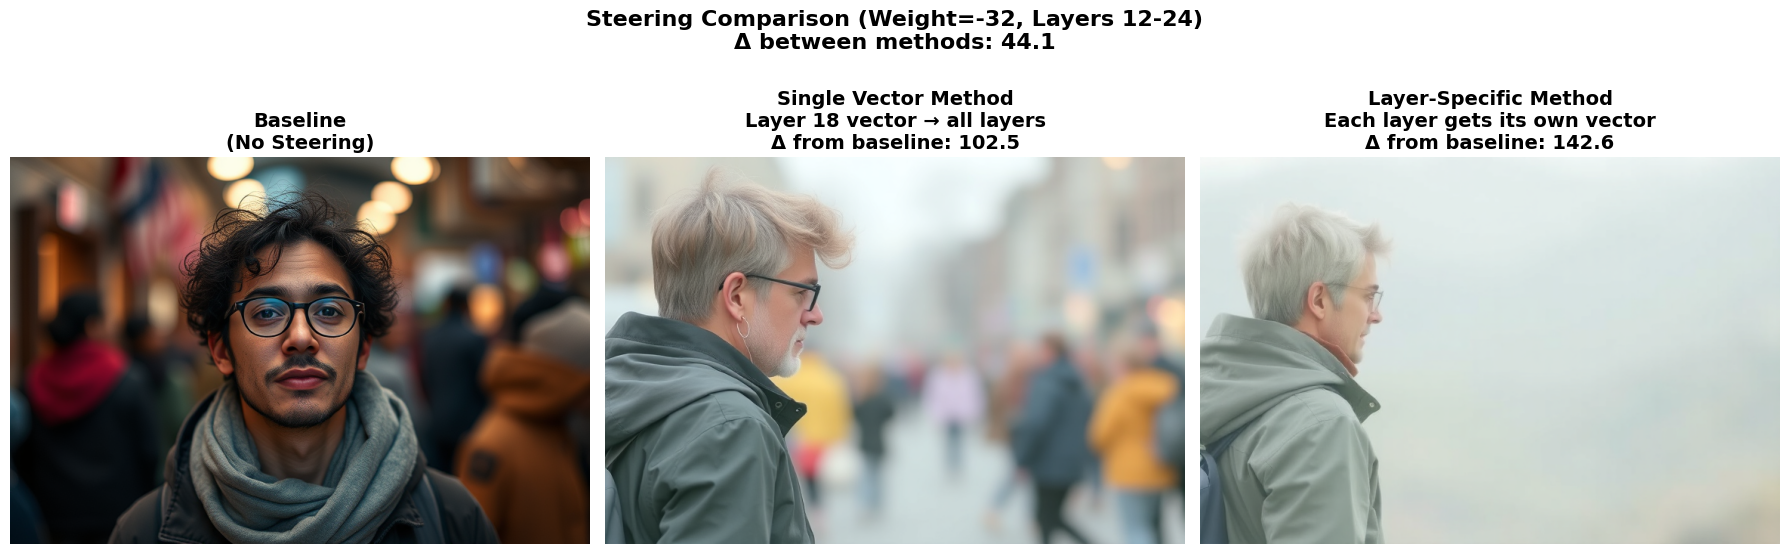


📊 COMPARISON METRICS

📏 Average Pixel Difference:
  Baseline → Single Vector:       102.47
  Baseline → Layer-Specific:      142.59
  Single Vector ↔ Layer-Specific:  44.14

🔍 Analysis:
  Layer-Specific steering had 39.2% stronger effect from baseline
  ✅ Significant visual difference between methods (Δ = 44.1)



In [ ]:
# =========================
# Build concept sweep combinations
# =========================
print("Loading concept vectors from cache...")
concept_vectors, concept_meta = vector_cache.load_all_vectors()
# Build all combinations using the config
concept_sweep_combinations = config.build_sweep_combinations(concept_vectors, concept_meta)

print(f"Total concept sweep combinations: {len(concept_sweep_combinations)}")

# Create DataFrame for inspection
concept_sweep_combinations_df = pd.DataFrame(
    concept_sweep_combinations,
    columns=["concept", "extracted_layer", "start_layer", "end_layer", "weight", "target", "concept_key"]
)
print("Sample combinations:")
display(concept_sweep_combinations_df)


Loading concept vectors from cache...
Total concept sweep combinations: 36
Sample combinations:


,concept,extracted_layer,start_layer,end_layer,weight,target,concept_key
0,age,18,18,18,0.0,image,age_L18_image
1,age,18,18,18,0.0,text,age_L18_text
2,age,18,18,18,0.0,both,age_L18_both
3,age,18,18,18,32.0,image,age_L18_image
4,age,18,18,18,32.0,text,age_L18_text
5,age,18,18,18,32.0,both,age_L18_both
6,age,18,18,18,64.0,image,age_L18_image
7,age,18,18,18,64.0,text,age_L18_text
8,age,18,18,18,64.0,both,age_L18_both
9,age,18,18,18,128.0,image,age_L18_image


In [ ]:
# =========================
# MAIN CONCEPT SWEEP (Core Workflow)
# =========================
import csv
import time
from PIL import Image
from flux_steering.image_utils import generate_baseline_image
from flux_steering.vector_utils import generate_steered_image
from flux_steering.file_utils import mean_or_none

# Load resume set if continuing
completed_keys = set()
# if config.results_csv.exists():
#     if config.run_mode == "restart":
#         print("[RUN_MODE=restart] Ignoring old checkpoint, starting fresh.")
#         completed_keys = set()
#     else:  # continue
#         prev = pd.read_csv(config.results_csv, dtype=str)
#         for _, r in prev.iterrows():
#             completed_keys.add(_row_key(
#                 r.get("concept", ""),
#                 r.get("extracted_layer", ""),
#                 int(r.get("start_layer", 0)),
#                 int(r.get("end_layer", 0)),
#                 r.get("weight", ""),
#                 r.get("steer_target", "")
#             ))
#         print(f"[RUN_MODE=continue] Loaded {len(completed_keys)} completed combos.")

# Load or generate baseline image
# Replace the single baseline generation with concept-specific baselines
baseline_images = {}

for concept, (base_prompt, pos_prompt, neg_prompt) in config.concept_suite.items():
    baseline_path = config.base_dir / f"baseline_{concept}.png"

    if baseline_path.exists() and config.run_mode != "restart":
        try:
            img = Image.open(baseline_path).convert("RGB")
            if img.size != (config.default_width, config.default_height):
                raise ValueError(f"Baseline size mismatch")
            baseline_images[concept] = img
            print(f"Baseline loaded for {concept} from {baseline_path}")
        except Exception as e:
            print(f"Baseline load failed for {concept} ({e}); regenerating...")
            img = pipe(
                prompt=base_prompt,  # Concept-specific base prompt!
                guidance_scale=config.guidance_scale,
                height=config.default_height,
                width=config.default_width,
                num_inference_steps=config.default_steps,
                generator=torch.Generator(device="cpu").manual_seed(config.default_seed),
            ).images[0]
            baseline_images[concept] = img
            if config.save_baseline_image:
                pil_to_uint8(img).save(baseline_path)
    else:
        img = pipe(
            prompt=base_prompt,  # Concept-specific base prompt!
            guidance_scale=config.guidance_scale,
            height=config.default_height,
            width=config.default_width,
            num_inference_steps=config.default_steps,
            generator=torch.Generator(device="cpu").manual_seed(config.default_seed),
        ).images[0]
        baseline_images[concept] = img
        if config.save_baseline_image:
            pil_to_uint8(img).save(baseline_path)

print(f"✅ Generated {len(baseline_images)} concept-specific baselines")

if config.run_mode == "restart" and config.results_csv.exists():
    print(f"[RUN_MODE=restart] Deleting old CSV to start fresh: {config.results_csv}")
    config.results_csv.unlink()

# Prepare CSV header
if not config.results_csv.exists():
    with open(config.results_csv, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "concept", "extracted_layer", "start_layer", "end_layer", "weight", "steer_target",
            "seed", "base_prompt", "neg_prompt",
            "delta_clip_score", "lpips", "dino_sim",
            "avg_norm_image", "w_image_eff", "ratio_image",
            "avg_norm_text", "w_text_eff", "ratio_text",
            "image_path", "error"
        ])

concept_results_list = []

print("\nStarting concept sweep (checkpointed, resumable)...")
start_time = time.time()

# MAIN LOOP
for idx, combo in enumerate(concept_sweep_combinations, start=1):
    concept, extracted_layer, start_layer, end_layer, weight, steer_target, concept_key = combo

    base_prompt, pos_prompt, neg_prompt = config.concept_suite[concept]
    baseline_image = baseline_images[concept]  # Use concept-specific baseline!

    # Handle vector fetching based on steer_target
    steering_vec = None
    if steer_target == "both":
        # For "both" target, construct dict with both image and text vectors
        img_key = f"{concept}_L{extracted_layer}_image"
        txt_key = f"{concept}_L{extracted_layer}_text"

        if img_key not in concept_vectors or txt_key not in concept_vectors:
            print(f"[skip] Missing vectors for 'both' target: {concept_key}")
            continue

        steering_vec = {
            "image": concept_vectors[img_key],
            "text": concept_vectors[txt_key]
        }
    else:
        # For "image" or "text" targets, use single vector
        if concept_key not in concept_vectors:
            print(f"[skip] Missing vector for key '{concept_key}'.")
            continue

        steering_vec = concept_vectors[concept_key]

    # Checkpointing
    key = _row_key(concept, extracted_layer, start_layer, end_layer, weight, steer_target)
    if key in completed_keys:
        continue

    # Initialize result variables
    error_msg, image_path = "", ""
    delta_clip = None
    lpips = None
    dino_sim = None
    avg_norm_image = None
    w_image_eff = None
    ratio_image = None
    avg_norm_text = None
    w_text_eff = None
    ratio_text = None

    try:
        steered_image, stats = generate_steered_image(
            pipe=pipe,
            prompt=base_prompt,
            start_layer=int(start_layer),
            end_layer=int(end_layer),
            weight=float(weight),
            steering_vector=steering_vec,
            height=config.default_height,
            width=config.default_width,
            inference_steps=config.default_steps,
            seed=config.default_seed,
            steer_target=steer_target
        )

        # Summarize per-stream stats
        avg_norm_image = mean_or_none(stats.get("avg_norm_image"))
        w_image_eff = mean_or_none(stats.get("w_image_eff"))
        ratio_image = mean_or_none(stats.get("ratio_image"))
        avg_norm_text = mean_or_none(stats.get("avg_norm_text"))
        w_text_eff = mean_or_none(stats.get("w_text_eff"))
        ratio_text = mean_or_none(stats.get("ratio_text"))

        # Save image if configured
        if config.save_steered_images:
            fname = build_image_filename(concept, extracted_layer, start_layer, end_layer, weight, steer_target, config.default_seed)
            out_path = save_image_unique(pil_to_uint8(steered_image), config.images_dir, fname)
            image_path = str(out_path.resolve())

        # Evaluate image
        target_prompt_concept_clip = pos_prompt
        delta_clip, lpips, dino_sim = evaluate_image_edits(steered_image, baseline_image, target_prompt_concept_clip)

    except Exception as e:
        delta_clip, lpips, error_msg = None, None, str(e)
        print(f"[error] {concept} ext={extracted_layer} L{start_layer}-{end_layer} w={weight}: {error_msg}")

    # Save results
    with open(config.results_csv, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            concept, extracted_layer,
            int(start_layer), int(end_layer),
            weight, str(steer_target),
            config.default_seed, base_prompt, neg_prompt,
            delta_clip, lpips, dino_sim, avg_norm_image, w_image_eff, ratio_image,
            avg_norm_text, w_text_eff, ratio_text,
            image_path, error_msg
        ])
    completed_keys.add(key)

    concept_results_list.append({
        "concept": concept,
        "extracted_layer": extracted_layer,
        "start_layer": int(start_layer),
        "end_layer": int(end_layer),
        "weight": float(weight),
        "steer_target": steer_target,
        "seed": config.default_seed,
        "base_prompt": base_prompt,
        "neg_prompt": neg_prompt,
        "delta_clip_score": delta_clip,
        "lpips": lpips,
        "dino_sim": dino_sim,
        "avg_norm_image": avg_norm_image,
        "w_image_eff": w_image_eff,
        "ratio_image": ratio_image,
        "avg_norm_text": avg_norm_text,
        "w_text_eff": w_text_eff,
        "ratio_text": ratio_text,
        "image_path": image_path,
        "error": error_msg or None
    })

elapsed = time.time() - start_time
print(f"\nSweep finished in {elapsed:.2f}s.")
print(f"Checkpoint file: {config.results_csv}")

concept_sweep_results_df = pd.DataFrame(concept_results_list)
display(concept_sweep_results_df.head())

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

✅ Generated 2 concept-specific baselines
[RUN_MODE=restart] Deleting old CSV to start fresh: /content/drive/MyDrive/Flux_Autosteering/results/concept_sweep_results.csv

Starting concept sweep (checkpointed, resumable)...


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (31 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]


Sweep finished in 57.50s.
Checkpoint file: /content/drive/MyDrive/Flux_Autosteering/results/concept_sweep_results.csv


,concept,extracted_layer,start_layer,end_layer,weight,steer_target,seed,base_prompt,neg_prompt,delta_clip_score,lpips,dino_sim,avg_norm_image,w_image_eff,ratio_image,avg_norm_text,w_text_eff,ratio_text,image_path,error
0,age,18,18,18,0.0,image,42,a photo of a person,a young person,0.001997,0.147414,0.963659,1722.742401,0.0,0.00000,6583.937622,0.0,0.000000,/content/drive/MyDrive/Flux_Autosteering/resul...,None
1,age,18,18,18,0.0,text,42,a photo of a person,a young person,0.001997,0.147414,0.963659,1722.742401,0.0,0.00000,6583.937622,0.0,0.000000,/content/drive/MyDrive/Flux_Autosteering/resul...,None
2,age,18,18,18,0.0,both,42,a photo of a person,a young person,0.001997,0.147414,0.963659,1722.742401,0.0,0.00000,6583.937622,0.0,0.000000,/content/drive/MyDrive/Flux_Autosteering/resul...,None
3,age,18,18,18,32.0,image,42,a photo of a person,a young person,0.010437,0.186892,0.931306,1719.171326,32.0,0.01907,6545.157959,32.0,0.005114,/content/drive/MyDrive/Flux_Autosteering/resul...,None
4,age,18,18,18,32.0,text,42,a photo of a person,a young person,0.005226,0.163400,0.952549,1720.340363,32.0,0.01906,6591.746216,32.0,0.005086,/content/drive/MyDrive/Flux_Autosteering/resul...,None


In [ ]:
# if 'config' in sys.modules:
#     del sys.modules['config']
# Force reimport
try:
    from flux_steering.visualization_utils import create_concept_grid, create_line_charts, create_scatter_plots
    print("✅ Successfully imported vector_utils")
except Exception as e:
    print(f"❌ Import failed: {e}")


✅ Successfully imported vector_utils


In [ ]:
import pandas as pd

# Read the CSV without header first
csv_path = '/content/drive/MyDrive/Flux_Autosteering/results/concept_sweep_results.csv'

# Read all lines
with open(csv_path, 'r') as f:
    lines = f.readlines()

# Fix the header (line 0) - add dino_sim after lpips
correct_header = "concept,extracted_layer,start_layer,end_layer,weight,steer_target,seed,base_prompt,neg_prompt,delta_clip_score,lpips,dino_sim,avg_norm_image,w_image_eff,ratio_image,avg_norm_text,w_text_eff,ratio_text,image_path,error\n"

# Replace the header
lines[0] = correct_header

# Write back
with open(csv_path, 'w') as f:
    f.writelines(lines)

print(f"Total lines: {len(lines)}")

✅ CSV header fixed! Added missing 'dino_sim' column.
Total lines: 109


In [ ]:
# Read the CSV file line by line to see line 74
with open('/content/drive/MyDrive/Flux_Autosteering/results/concept_sweep_results.csv', 'r') as f:
    lines = f.readlines()

print(f"Total lines in Drive CSV: {len(lines)}")
print(f"\nLine 74:")
if len(lines) >= 74:
    print(lines[73])  # Line 74 (0-indexed as 73)
    print(f"\nNumber of commas in line 74: {lines[73].count(',')}")

print(f"\nLine 1 (header) for comparison:")
print(lines[0])
print(f"Number of commas in header: {lines[0].count(',')}")

Total lines in Drive CSV: 37

Line 74:

Line 1 (header) for comparison:
concept,extracted_layer,start_layer,end_layer,weight,steer_target,seed,base_prompt,neg_prompt,delta_clip_score,lpips,dino_sim,avg_norm_image,w_image_eff,ratio_image,avg_norm_text,w_text_eff,ratio_text,image_path,error

Number of commas in header: 19


Module reloaded!
Creating visualizations...
Loaded 36 rows from /content/drive/MyDrive/Flux_Autosteering/results/concept_sweep_results.csv

Filtering 36 rows...
  cfg_targets: ['image', 'text', 'both']
  Applying cfg_targets filter: ['image', 'text', 'both']
  Unique steer_target values before filter: ['image', 'text', 'both']
  After cfg_targets filter: 36 rows


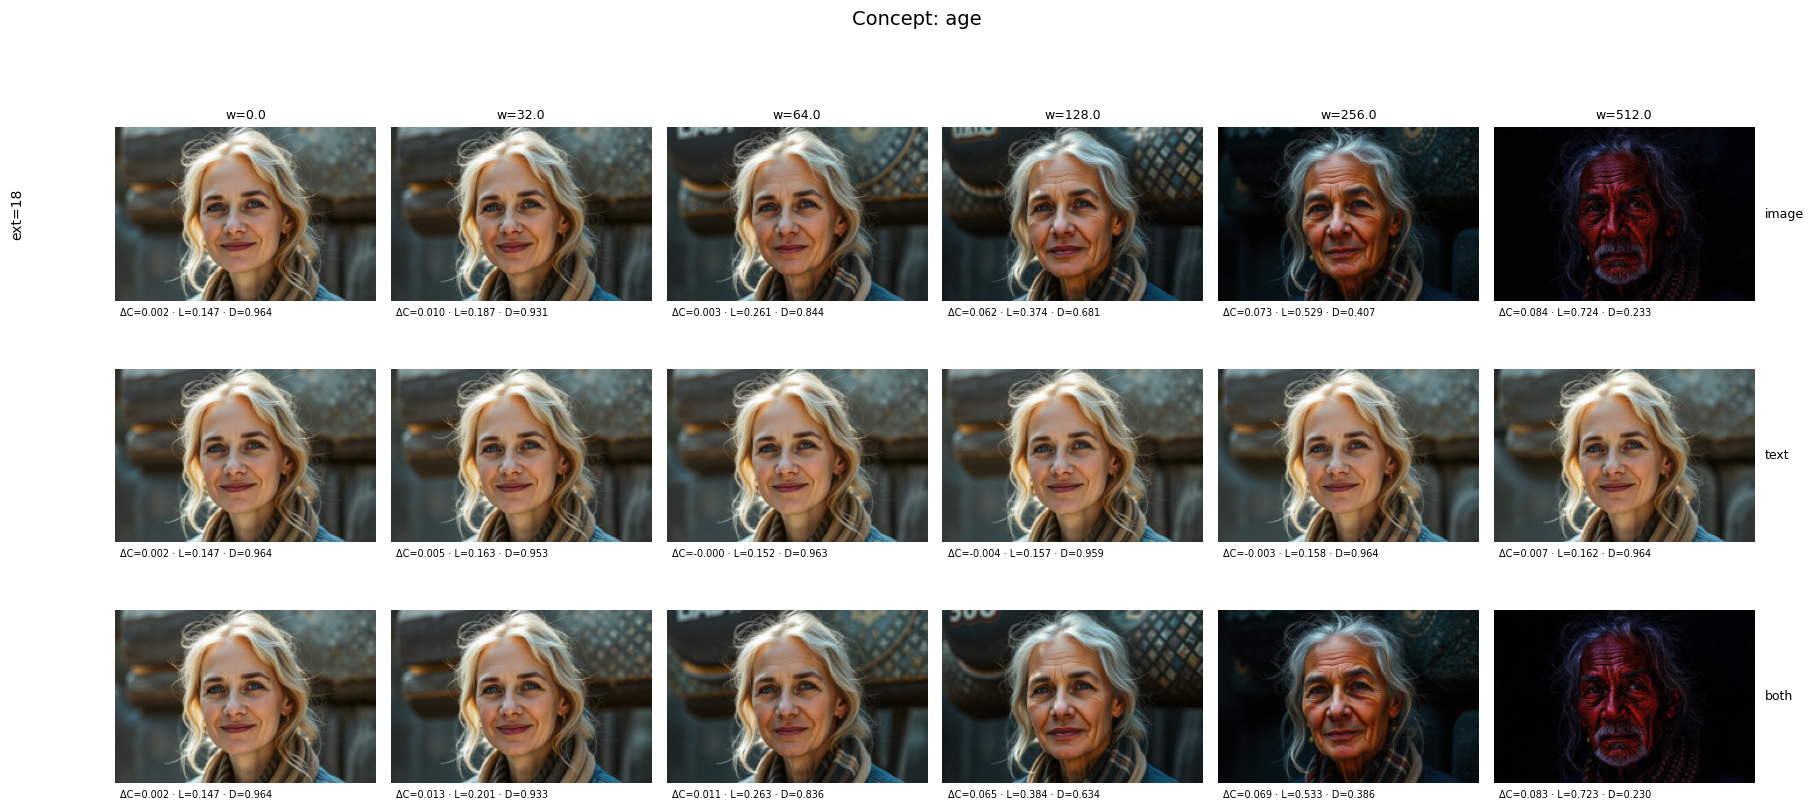

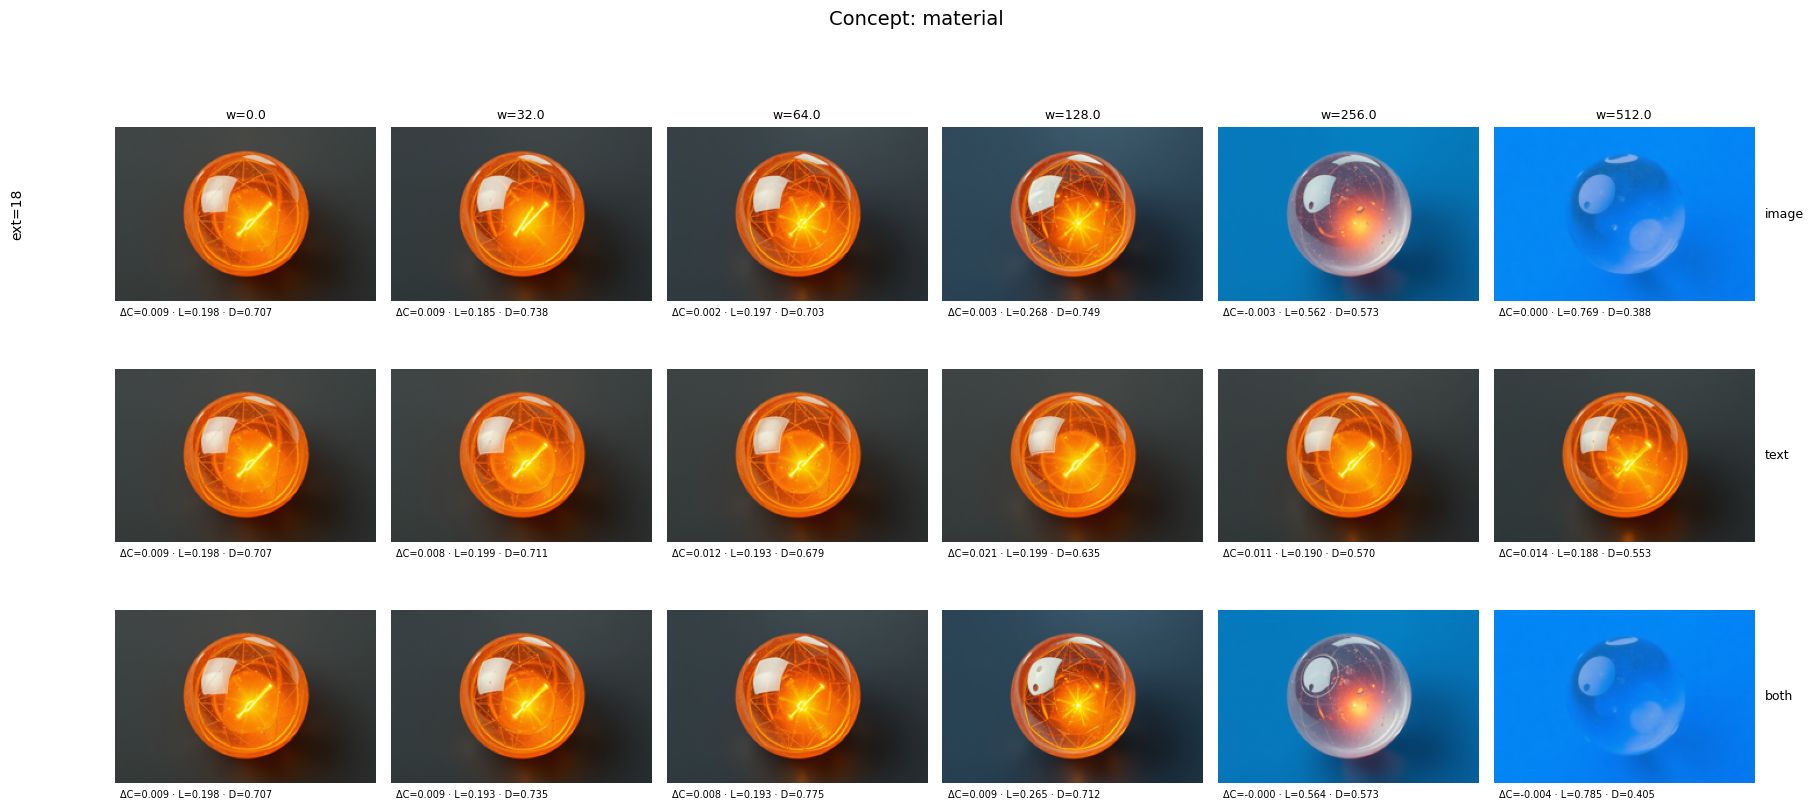

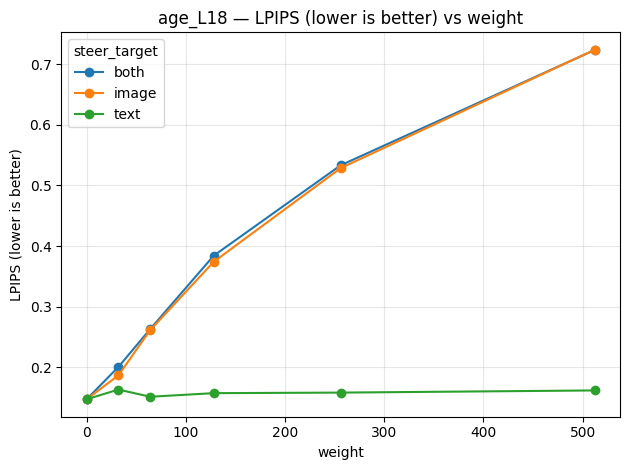

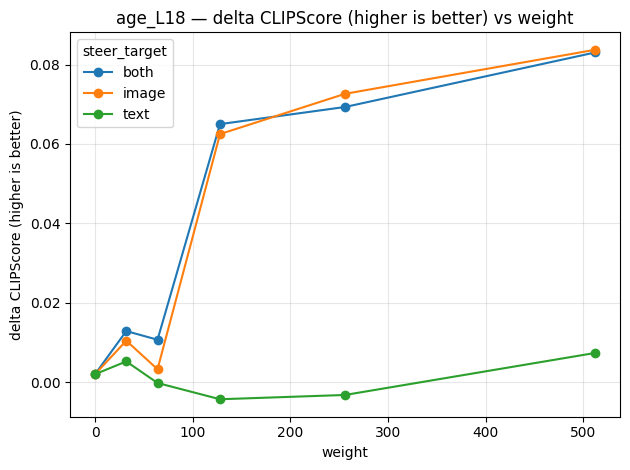

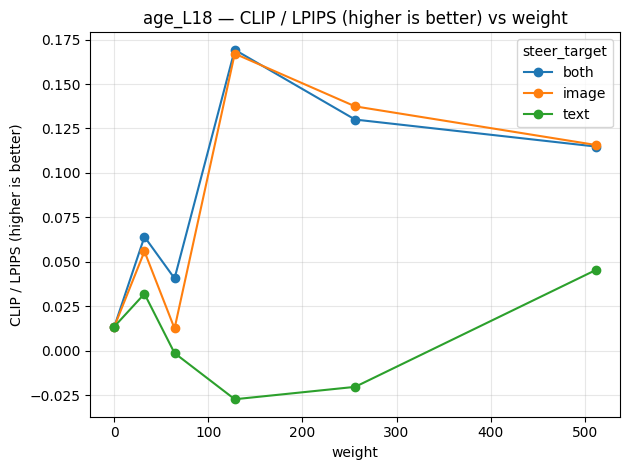

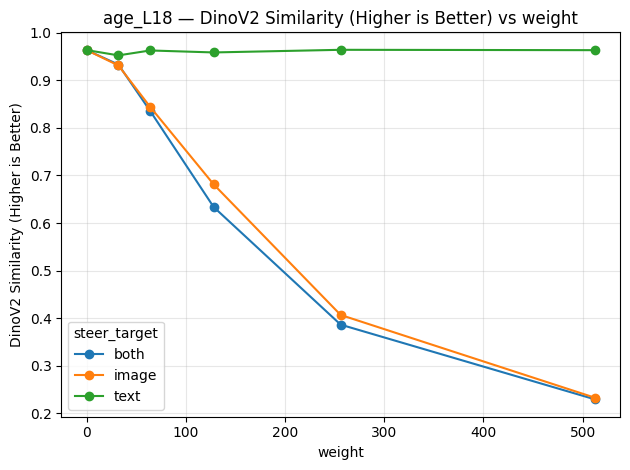

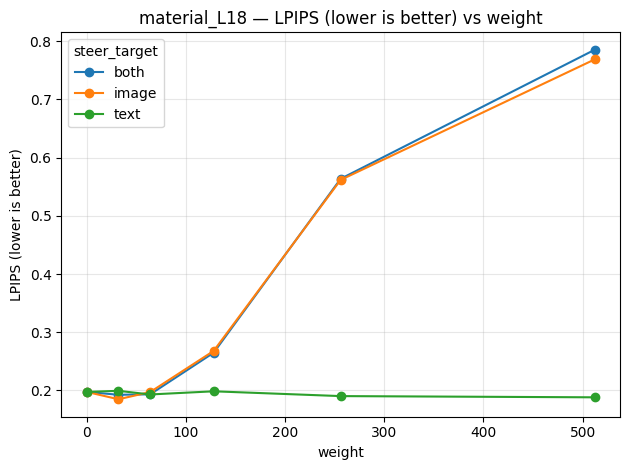

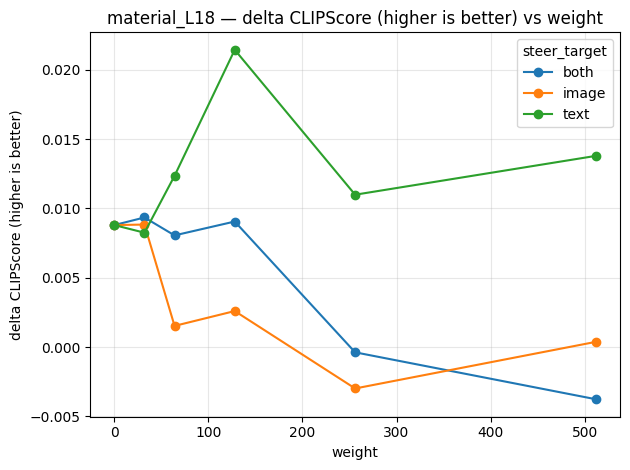

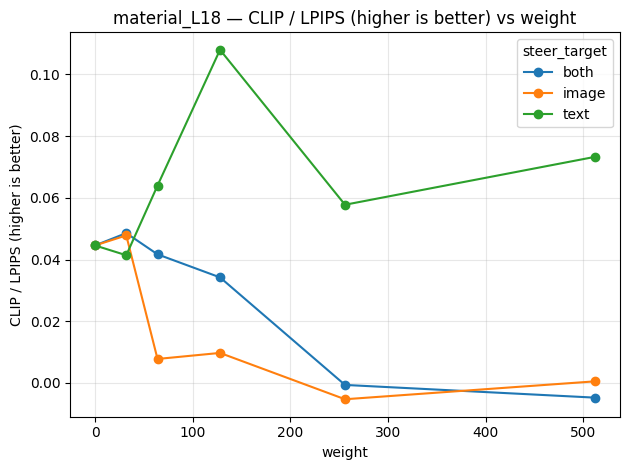

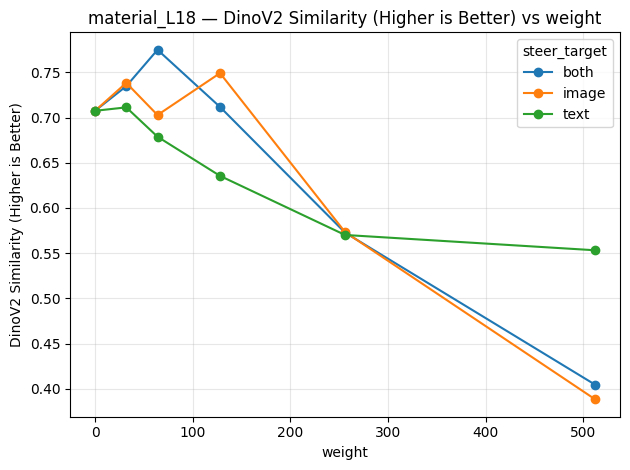

Saved 8 plots to: /content/drive/MyDrive/Flux_Autosteering/results/plots


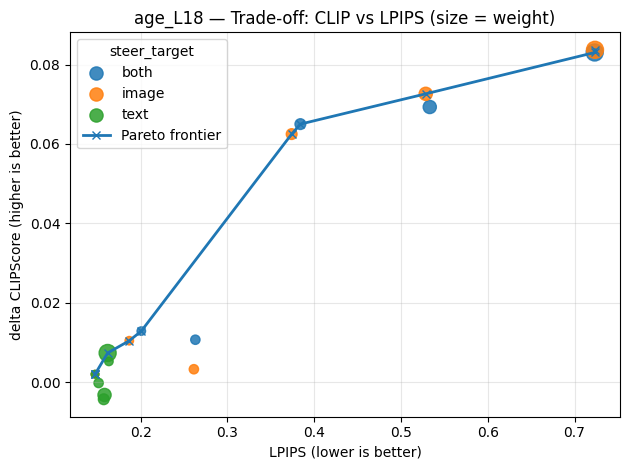

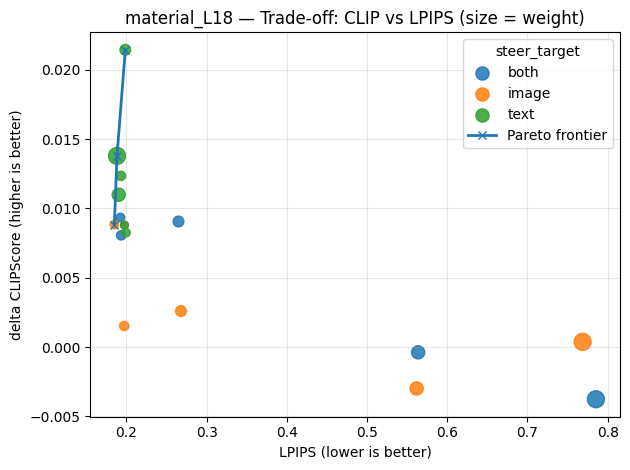

Saved 2 scatter plots to: /content/drive/MyDrive/Flux_Autosteering/results/plots
✅ All visualizations complete.


In [ ]:
# =========================
# FORCE RELOAD MODULE
# =========================
import sys
import importlib

# Remove cached module
if 'flux_steering.visualization_utils' in sys.modules:
    del sys.modules['flux_steering.visualization_utils']

# Reload fresh
from flux_steering.visualization_utils import create_concept_grid, create_line_charts, create_scatter_plots

print("Module reloaded!")

# =========================
# VISUALIZATION: All Charts and Grids
# =========================
print("Creating visualizations...")

# Create concept grids
create_concept_grid(
    results_csv_path=config.results_csv,
    images_dir=config.images_dir
)

# Create line charts
create_line_charts(
    results_csv_path=config.results_csv,
    output_dir=config.base_dir / "plots"
)

# Create scatter plots
create_scatter_plots(
    results_csv_path=config.results_csv,
    output_dir=config.base_dir / "plots"
)

print("✅ All visualizations complete.")

In [ ]:
# =========================
# COMPARISON: Layer-Specific vs Single Vector Steering
# =========================
import matplotlib.pyplot as plt
import numpy as np

# Configuration
POS_PROMPT = "A photo of an old person with wrinkles"  # What to steer TOWARD/AWAY FROM
NEG_PROMPT = "A photo of a person"  # Neutral/baseline
TEST_PROMPT = "A photo of a person"  # Image generation prompt
START_LAYER = 12
END_LAYER = 24
WEIGHT = -32  # Negative = steer away from POS_PROMPT, Positive = steer toward
SEED = 42

print("="*70)
print(f"COMPARING STEERING METHODS")
print("="*70)
print(f"Steering: {POS_PROMPT}")
print(f"Baseline: {NEG_PROMPT}")
print(f"Layers: {START_LAYER}-{END_LAYER}")
print(f"Weight: {WEIGHT}")

# Step 1: Extract layer-specific vectors
print(f"\n🧭 Extracting layer-specific vectors for layers {START_LAYER}-{END_LAYER}...")
layer_vectors = {}

for layer_idx in range(START_LAYER, END_LAYER + 1):
    layer_vectors[layer_idx] = contrastive_steering_vector(
        transformer=pipe.transformer,
        layer_indices=layer_idx,
        pos_prompt=POS_PROMPT,
        neg_prompt=NEG_PROMPT,
        pipe=pipe,
        stream="both",
        steps=config.default_steps,
        H=config.default_height,
        W=config.default_width,
        seed=SEED
    )
    print(f"  Layer {layer_idx}: ✓")

print(f"✅ Extracted {len(layer_vectors)} layer-specific vectors")

# Step 2: Extract single vector from middle layer
SINGLE_LAYER = (START_LAYER + END_LAYER) // 2  # Use middle layer
print(f"\n🧭 Extracting single vector from layer {SINGLE_LAYER}...")
single_vector = contrastive_steering_vector(
    transformer=pipe.transformer,
    layer_indices=SINGLE_LAYER,
    pos_prompt=POS_PROMPT,
    neg_prompt=NEG_PROMPT,
    pipe=pipe,
    stream="both",
    steps=config.default_steps,
    H=config.default_height,
    W=config.default_width,
    seed=SEED
)
print(f"✅ Extracted single vector from layer {SINGLE_LAYER}")

# Step 3: Generate baseline image (no steering)
print(f"\n🎨 Generating baseline image...")
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
baseline_image = pipe(
    prompt=TEST_PROMPT,
    num_inference_steps=config.default_steps,
    height=config.default_height,
    width=config.default_width,
    guidance_scale=0.0,
    generator=generator
).images[0]
print("✅ Baseline generated")

# Step 4: Generate with single vector steering
print(f"\n🎨 Generating with SINGLE VECTOR (layer {SINGLE_LAYER} → all layers)...")
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
image_single, stats_single = generate_steered_image(
    pipe=pipe,
    generator=generator,
    prompt=TEST_PROMPT,
    start_layer=START_LAYER,
    end_layer=END_LAYER,
    weight=WEIGHT,
    steering_vector=single_vector,  # Same vector for all layers
    height=config.default_height,
    width=config.default_width,
    inference_steps=config.default_steps,
    steer_target="both"
)
print(f"✅ Single vector steering complete")

# Step 5: Generate with layer-specific steering
print(f"\n🎨 Generating with LAYER-SPECIFIC VECTORS (each layer gets its own)...")
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
image_layerspec, stats_layerspec = generate_steered_image(
    pipe=pipe,
    generator=generator,
    prompt=TEST_PROMPT,
    start_layer=START_LAYER,
    end_layer=END_LAYER,
    weight=WEIGHT,
    steering_vector=layer_vectors,  # Dict: {layer_idx: vector}
    height=config.default_height,
    width=config.default_width,
    inference_steps=config.default_steps,
    steer_target="both"
)
print(f"✅ Layer-specific steering complete")

# Step 6: Calculate metrics
print(f"\n📊 Calculating metrics...")

# Calculate pixel differences
diff_baseline_single = np.abs(np.array(baseline_image).astype(float) - np.array(image_single).astype(float)).mean()
diff_baseline_layerspec = np.abs(np.array(baseline_image).astype(float) - np.array(image_layerspec).astype(float)).mean()
diff_single_layerspec = np.abs(np.array(image_single).astype(float) - np.array(image_layerspec).astype(float)).mean()

# Step 7: Visualize comparison
print(f"\n📈 Creating visualization...")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Baseline
axes[0].imshow(baseline_image)
axes[0].set_title(f"Baseline\n(No Steering)", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Single vector
axes[1].imshow(image_single)
axes[1].set_title(
    f"Single Vector Method\n"
    f"Layer {SINGLE_LAYER} vector → all layers\n"
    f"Δ from baseline: {diff_baseline_single:.1f}",
    fontsize=14,
    fontweight='bold'
)
axes[1].axis('off')

# Layer-specific
axes[2].imshow(image_layerspec)
axes[2].set_title(
    f"Layer-Specific Method\n"
    f"Each layer gets its own vector\n"
    f"Δ from baseline: {diff_baseline_layerspec:.1f}",
    fontsize=14,
    fontweight='bold'
)
axes[2].axis('off')

plt.suptitle(
    f"Steering Comparison (Weight={WEIGHT}, Layers {START_LAYER}-{END_LAYER})\n"
    f"Δ between methods: {diff_single_layerspec:.1f}",
    fontsize=16,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.show()

# Step 8: Print detailed metrics
print("\n" + "="*70)
print("📊 COMPARISON METRICS")
print("="*70)

print(f"\n📏 Average Pixel Difference:")
print(f"  Baseline → Single Vector:       {diff_baseline_single:.2f}")
print(f"  Baseline → Layer-Specific:      {diff_baseline_layerspec:.2f}")
print(f"  Single Vector ↔ Layer-Specific:  {diff_single_layerspec:.2f}")

# Determine which method had stronger effect
if diff_baseline_layerspec > diff_baseline_single:
    stronger = "Layer-Specific"
    diff_pct = ((diff_baseline_layerspec - diff_baseline_single) / diff_baseline_single) * 100
else:
    stronger = "Single Vector"
    diff_pct = ((diff_baseline_single - diff_baseline_layerspec) / diff_baseline_layerspec) * 100

print(f"\n🔍 Analysis:")
print(f"  {stronger} steering had {diff_pct:.1f}% stronger effect from baseline")

if diff_single_layerspec > 5.0:
    print(f"  ✅ Significant visual difference between methods (Δ = {diff_single_layerspec:.1f})")
else:
    print(f"  ⚠️  Similar results between methods (Δ = {diff_single_layerspec:.1f})")

print("\n" + "="*70)

